# Neural networks — LAB 1: Neural networks for regression
ESIEA x SKEMA — MSc AIBT

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
plt.rcParams["figure.figsize"] = (8, 4.5)

## Part 1 – Dataset
### Q1. Load both datasets

In [2]:
data1 = np.loadtxt("LAB1_datasets/LAB1_dataset1.txt")
data2 = np.loadtxt("LAB1_datasets/LAB1_dataset2.txt")

X1, y1 = data1[:, :1], data1[:, 1]   # first column = feature, second = target
X2, y2 = data2[:, :1], data2[:, 1]

print("Dataset 1:", X1.shape[0], "samples")
print("Dataset 2:", X2.shape[0], "samples")

Dataset 1: 167 samples
Dataset 2: 177 samples


**Answer.** Dataset 1 contains **167 samples  and dataset 2 contains  177 samples . Each has a single feature (column 1) and a quantitative target (column 2).

### Q2. Plot both datasets

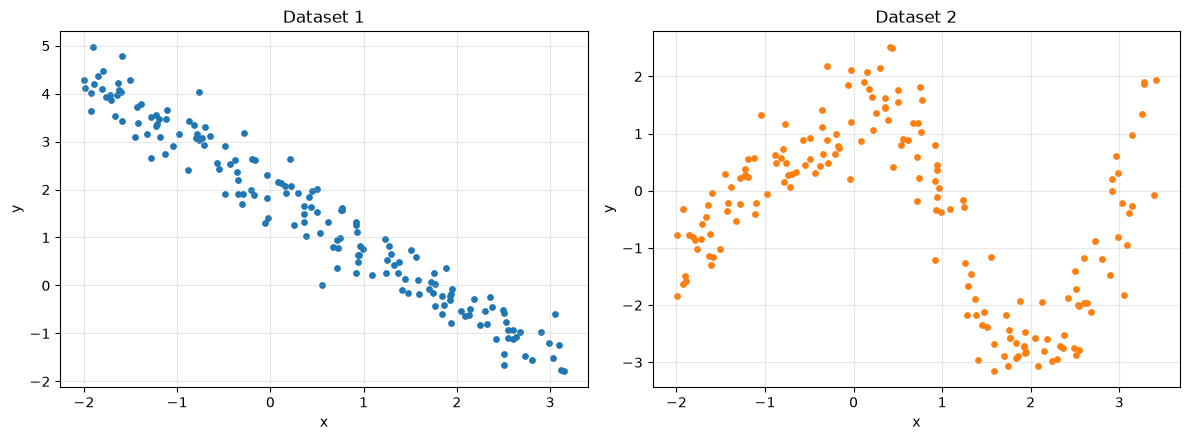

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
col1, col2 = "tab:blue", "tab:orange"
for ax, X, y, name, color in [(axes[0], X1, y1, "Dataset 1", col1), (axes[1], X2, y2, "Dataset 2", col2)]:
    ax.scatter(X, y, s=15, c=color)
    ax.set_title(name); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Q3. Which dataset is not suited to a multi-layer perceptron?

In [4]:
for name, X, y in [("Dataset 1", X1, y1), ("Dataset 2", X2, y2)]:
    print(name, "- R² of a simple linear regression:", round(LinearRegression().fit(X, y).score(X, y), 3))

Dataset 1 - R² of a simple linear regression: 0.952
Dataset 2 - R² of a simple linear regression: 0.122


 Answer: A multi-layer perceptron is **not recommended for dataset 1**. Its points lie along a straight decreasing line plus noise: a simple linear regression already explains about 95% of the variance (R² = 0.95). An MLP would add many parameters, a random initialisation and a long iterative training to learn something a two-parameter model captures exactly. It would also risk fitting the noise and would be less interpretable. The better-suited model is a **linear regression** (ordinary least squares), which has a closed-form solution.

Dataset 2, by contrast, is clearly non-linear (it rises, falls, then rises again), and a linear model only reaches R² = 0.12. This is where a neural network is useful.

## Part 2 – Visualization
### Q4. Plotting function

In [5]:
def plot_predictions(model, X, y_true, title=None):
    """True targets in green, model predictions in gray."""
    y_pred = model.predict(X)
    order = np.argsort(X[:, 0])
    plt.figure()
    plt.scatter(X[:, 0], y_true, color="red", s=15, label="true values")
    plt.scatter(X[:, 0], y_pred, color="blue", s=15, label="predicted values")
    plt.xlabel("feature x"); plt.ylabel("target y")
    if title: plt.title(title)
    plt.legend(); plt.grid(alpha=.3); plt.show()

### Q5. Linear model on dataset 1

y = -1.164 x + 1.995
R² = 0.952


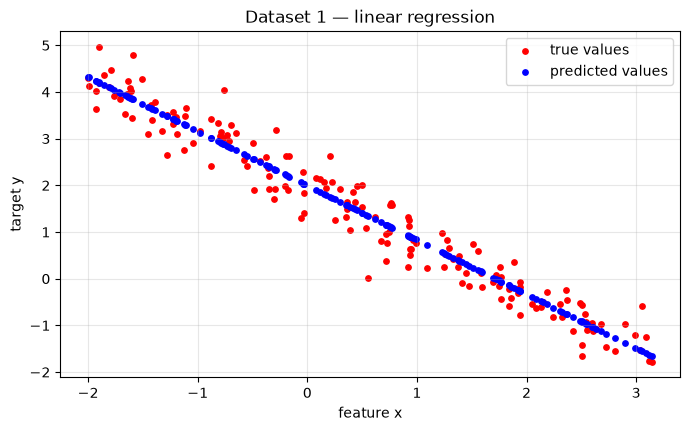

In [6]:
lin = LinearRegression().fit(X1, y1)
print(f"y = {lin.coef_[0]:.3f} x + {lin.intercept_:.3f}")
print("R² =", round(lin.score(X1, y1), 3))
plot_predictions(lin, X1, y1, "Dataset 1 — linear regression")

**Conclusion.** The linear model fits dataset 1 very well. The fitted line is y ≈ −1.16x + 2.00 with R² ≈ 0.95. The gray predictions run through the middle of the green cloud, and the remaining error is just the noise around the line. A neural network could not do meaningfully better here, which confirms the choice made in Q3.

_From here on, we work on  dataset 2 ._

### Q6. Neural network

In [ ]:
def make_mlp(n_neurons=30, random_state=42,  kw):
    params = dict(hidden_layer_sizes=(n_neurons,), activation="relu",
                  learning_rate="adaptive", random_state=random_state,
                  max_iter=10_000, warm_start=True)
    params.update(kw)
    return MLPRegressor( params)

mlp = make_mlp()
mlp

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(30,)"
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'adaptive'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",10000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previouscall to fit as initialization, otherwise, just erase theprevious solution. See :term:`the Glossary <warm_start>`.",True
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",

Notes on the parameters:
- `hidden_layer_sizes=(30,)`: one hidden layer of 30 neurons.
- `activation='relu'`: ReLU activation.
- `learning_rate='adaptive'`: adaptive learning rate. In scikit-learn this option is only used by the `sgd` solver. The default solver, **Adam**, already adapts the step size of each parameter on its own.
- `random_state=42`: reproducibility.
- `max_iter=10_000`.
- `warm_start=True`: a new call to `fit` continues from the current weights instead of starting over.

### Q7. Train on all the data and display

Iterations: 1239 | R² on the full dataset: 0.84


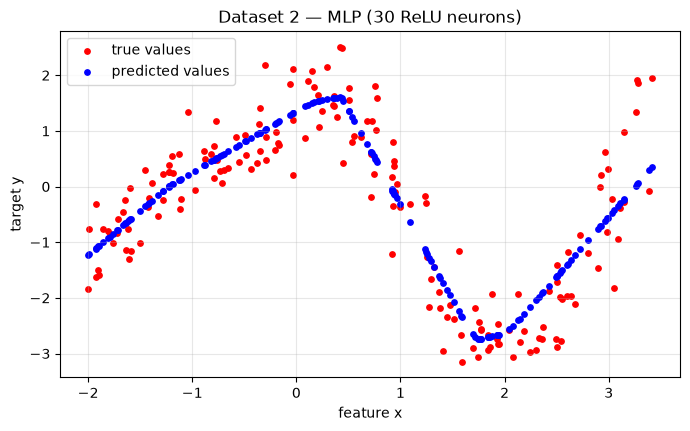

In [9]:
mlp.fit(X2, y2)
print("Iterations:", mlp.n_iter_, "| R² on the full dataset:", round(mlp.score(X2, y2), 3))
plot_predictions(mlp, X2, y2, "Dataset 2 — MLP (30 ReLU neurons)")

**Interpretation.** The network captures the overall non-linear shape of dataset 2: the rise up to x ≈ 0.4, the fall down to x ≈ 1.8, and the rise again afterwards. It reaches R² ≈ 0.84, compared with 0.12 for a linear model. Because of the ReLU activation, the prediction is a **piecewise-linear curve**, made of small straight segments joined at "kinks".

The fit is still imperfect: the peaks are flattened and the network **underfits the right end** (x > 3), where the true values rise much faster than the prediction. Training stopped after only ~1,200 iterations. The default stopping rule (10 epochs without improving the loss by more than `tol=1e-4`) halted it before convergence; the loss curve in Q9 is still going down when it stops.

### Q8. Number of weights and biases

In [9]:
n_w = sum(w.size for w in mlp.coefs_)
n_b = sum(b.size for b in mlp.intercepts_)
print("weights per layer:", [w.shape for w in mlp.coefs_], "->", n_w)
print("biases per layer :", [b.shape for b in mlp.intercepts_], "->", n_b)
print("total parameters :", n_w + n_b)

weights per layer: [(1, 30), (30, 1)] -> 60
biases per layer : [(30,), (1,)] -> 31
total parameters : 91


**Answer.** The network is 1 input → 30 hidden neurons → 1 output.
- Input → hidden: 1 × 30 = **30 weights** + **30 biases** (one per hidden neuron).
- Hidden → output: 30 × 1 = **30 biases (weight in hidden layer)** + **1 bias**.

Total: **60 weights and 31 biases, i.e. 91 trainable parameters.**

## Part 3 – Training process
### Q9. Loss curve of the previous model

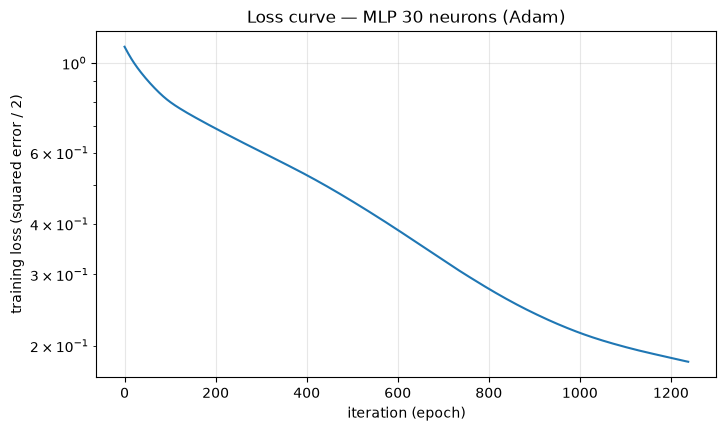

In [10]:
plt.plot(mlp.loss_curve_)
plt.xlabel("iteration (epoch)"); plt.ylabel("training loss (squared error / 2)")
plt.title("Loss curve — MLP 30 neurons (Adam)"); plt.yscale("log"); plt.grid(alpha=.3); plt.show()

The loss (half the mean squared error) decreases steadily but is **still decreasing when training stops** (~1,200 iterations). This confirms what we saw in Q7: the stopping criterion was triggered before full convergence, so the model is slightly undertrained.

### Q10. Comparing optimisation processes

SGD, momentum 0.3      iterations=10000  final loss=0.4212  R²=0.632
SGD, momentum 0.9      iterations= 6241  final loss=0.1531  R²=0.866
SGD, momentum 0.99     iterations= 2188  final loss=0.1426  R²=0.875
SGD, momentum 0.999    iterations= 4877  final loss=0.1359  R²=0.881
Adam                   iterations= 3644  final loss=0.1451  R²=0.873


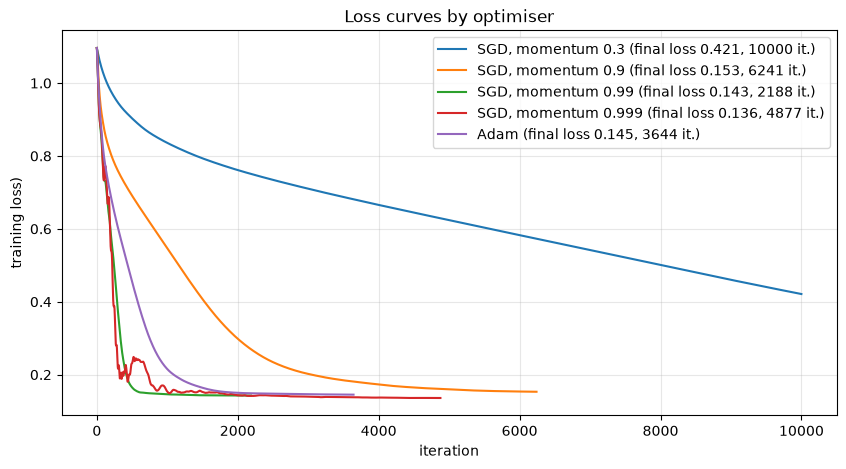

In [41]:
common = dict(n_iter_no_change=1000, tol=1e-5, max_iter=10_000)
configs = {
    "SGD, momentum 0.3":   dict(solver="sgd", learning_rate="constant", momentum=0.3),
    "SGD, momentum 0.9":   dict(solver="sgd", learning_rate="constant", momentum=0.9),
    "SGD, momentum 0.99":  dict(solver="sgd", learning_rate="constant", momentum=0.99),
    "SGD, momentum 0.999": dict(solver="sgd", learning_rate="constant", momentum=0.999),
    "Adam":                dict(solver="adam"),
}
models = {}
plt.figure(figsize=(10, 5))
for name, cfg in configs.items():
    m = make_mlp(**cfg, **common).fit(X2, y2)
    models[name] = m
    plt.plot(m.loss_curve_, label=f"{name} (final loss {m.loss_:.3f}, {m.n_iter_} it.)")
    print(f"{name:22s} iterations={m.n_iter_:5d}  final loss={m.loss_:.4f}  R²={m.score(X2, y2):.3f}")
#plt.yscale("log"); 
plt.xlabel("iteration"); plt.ylabel("training loss)")
plt.title("Loss curves by optimiser"); plt.legend(); plt.grid(alpha=.3); plt.show()

SGD, momentum 0.99     iterations= 2188  final loss=0.1426  R²=0.875
SGD, momentum 0.999    iterations= 4877  final loss=0.1359  R²=0.881
Adam                   iterations= 3644  final loss=0.1451  R²=0.873


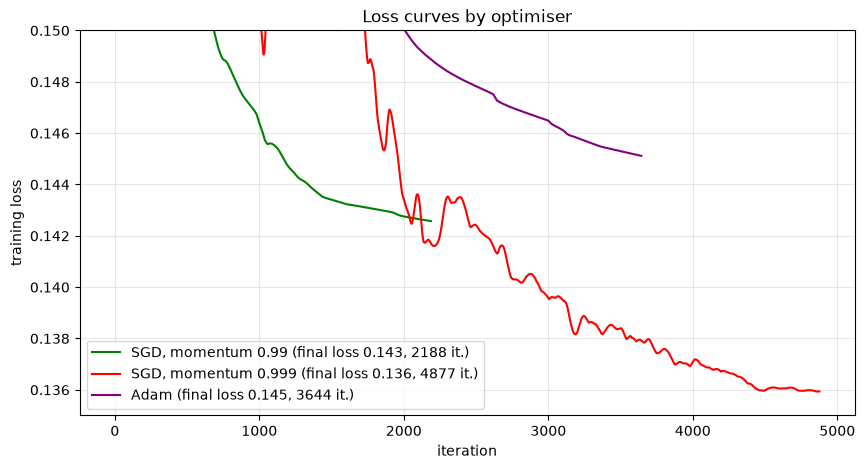

In [32]:
common = dict(n_iter_no_change=1000, tol=1e-5, max_iter=10_000)
configs = {
    "SGD, momentum 0.99":  dict(solver="sgd", learning_rate="constant", momentum=0.99),
    "SGD, momentum 0.999": dict(solver="sgd", learning_rate="constant", momentum=0.999),
    "Adam":                dict(solver="adam"),
}
models = {}
colors = {"SGD, momentum 0.99": "green", "SGD, momentum 0.999": "red", "Adam": "purple"}
plt.figure(figsize=(10, 5))
for name, cfg in configs.items():
    m = make_mlp(**cfg, **common).fit(X2, y2)
    models[name] = m
    plt.plot(m.loss_curve_, color=colors[name], label=f"{name} (final loss {m.loss_:.3f}, {m.n_iter_} it.)")
    print(f"{name:22s} iterations={m.n_iter_:5d}  final loss={m.loss_:.4f}  R²={m.score(X2, y2):.3f}")
plt.ylim(0.135, 0.150); 
plt.xlabel("iteration"); plt.ylabel("training loss")
plt.title("Loss curves by optimiser"); plt.legend(); plt.grid(alpha=.3); plt.show()

SGD, momentum 0.99     iterations= 3101  final loss=0.1420  R²=0.876
SGD, momentum 0.999    iterations= 7421  final loss=0.1350  R²=0.882
Adam                   iterations= 8675  final loss=0.1422  R²=0.876


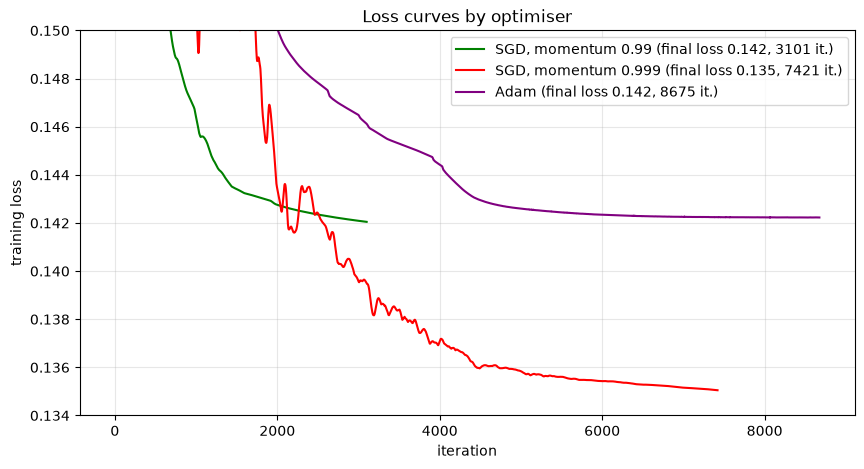

In [50]:
common = dict(n_iter_no_change=1000, tol=1e-6, max_iter=10_000)
configs = {
    "SGD, momentum 0.99":  dict(solver="sgd", learning_rate="constant", momentum=0.99),
    "SGD, momentum 0.999": dict(solver="sgd", learning_rate="constant", momentum=0.999),
    "Adam":                dict(solver="adam"),
}
models = {}
colors = {"SGD, momentum 0.99": "green", "SGD, momentum 0.999": "red", "Adam": "purple"}
plt.figure(figsize=(10, 5))
for name, cfg in configs.items():
    m = make_mlp(**cfg, **common).fit(X2, y2)
    models[name] = m
    plt.plot(m.loss_curve_, color=colors[name], label=f"{name} (final loss {m.loss_:.3f}, {m.n_iter_} it.)")
    print(f"{name:22s} iterations={m.n_iter_:5d}  final loss={m.loss_:.4f}  R²={m.score(X2, y2):.3f}")
plt.ylim(0.134, 0.150); 
plt.xlabel("iteration"); plt.ylabel("training loss")
plt.title("Loss curves by optimiser"); plt.legend(); plt.grid(alpha=.3); plt.show()

### Analysis (convergence criterion of 1000 it not change):
- the first one in  blue took our max iterations of 1000 and its training loss seems too weak
- The second one in orange with a momentum 0.9 decrease faster with 6241 it final loss seems to high compared to the next
- the third one in green seems to be the best in decreasing / iteration and still stable at the end for 2188 it (min of our test) for us we would prioritize this one SGB momentum = 0.99
- the fourth one in red with a momentum of 0.999 is not smooth at all and decreased/ increase a lot all iterations long. Similar to a rollercoaster curve still score the lower training loss among all solvers. Uncertain chose this solver at this moment, maybe change the tolerance to dedice.
- Last but not least the Adam (adaptative moment estimation) which we wanted to prioritize before testing has a good decreasing curve but still slower than ou 0.99 momentum.

### Q11. Low-momentum SGD

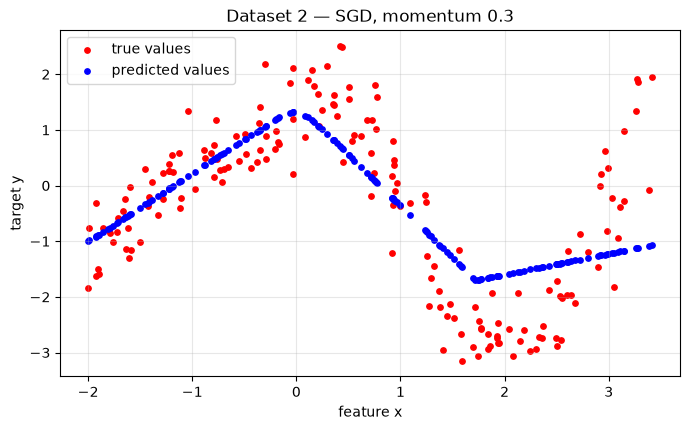

In [12]:
plot_predictions(models["SGD, momentum 0.3"], X2, y2, "Dataset 2 — SGD, momentum 0.3")

**Explanation.** With a constant learning rate and low momentum (0.3), each update is a small, plain gradient step with almost no accumulated velocity. Learning is therefore **very slow**. After the full 10,000 iterations, the loss (0.42) is still far above the other solvers (≈0.14–0.15), and the curve is still going down.

The model is **underfitted**. It has only learnt the first bump; between x ≈ 1.8 and x ≈ 3.4 it predicts an almost flat line around −1.5. It misses both the deep minimum (≈ −3) and the final rise (R² ≈ 0.63). With more iterations it would keep improving, but the cost would be very high.

### Q12. Very-high-momentum SGD

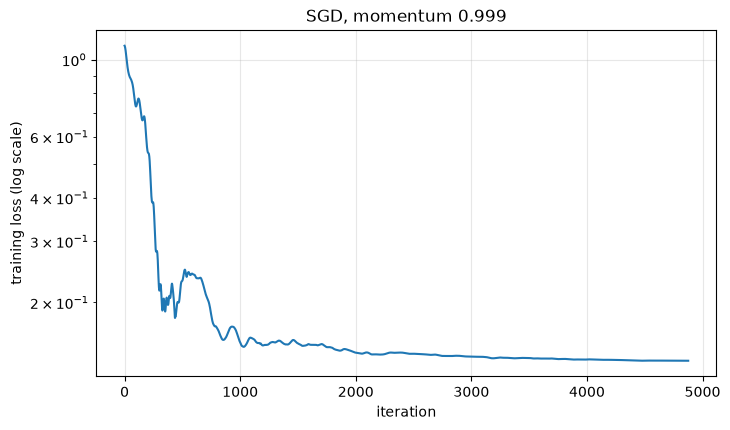

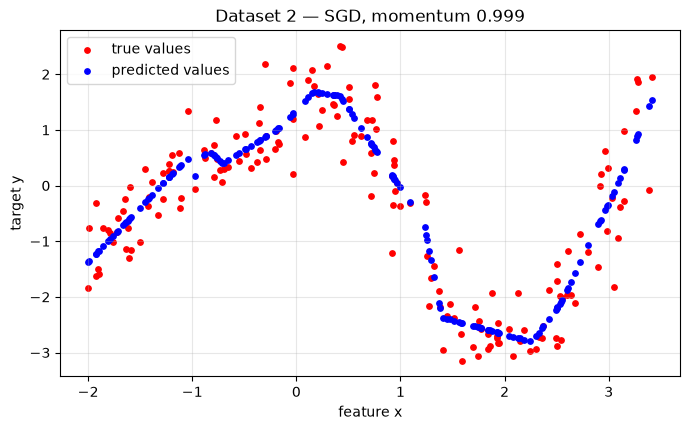

In [13]:
plt.plot(models["SGD, momentum 0.999"].loss_curve_)
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("training loss (log scale)")
plt.title("SGD, momentum 0.999"); plt.grid(alpha=.3); plt.show()
plot_predictions(models["SGD, momentum 0.999"], X2, y2, "Dataset 2 — SGD, momentum 0.999")

**Explanation.** With momentum 0.999, each update keeps 99.9% of the previous velocity. The optimiser behaves like a very heavy ball rolling down the loss surface: it **accelerates strongly** (the loss drops very fast in the first ~300 iterations) but **cannot brake**. It overshoots the minima, climbs back up the walls of the valley and oscillates. That explains the **bumps and spikes** on the curve, in particular the loss going back up from ≈0.19 to ≈0.25 around iterations 400–700.

The oscillations are slowly damped and the loss eventually stabilises at the lowest value of all runs (≈0.136). This only happens because we set `n_iter_no_change=1000`. With the default patience, training would probably have stopped during one of the bumps.

### Q13. Best optimisation process

**Answer.** In our case, **SGD with momentum 0.99** is the best compromise. It converges the fastest (loss ≈0.14 after only ~600 iterations), its curve is smooth, and it stops after 2,188 iterations with a loss almost equal to the best one.

- Momentum 0.999 reaches a marginally lower final loss (0.136 vs 0.143), but only after violent oscillations and more than twice as many iterations. The difference is negligible and comes from fitting the training noise.
- **Adam** (0.145) is a very close second. It is smooth, reliable and needs no momentum tuning, which is why it is the default choice in practice.
- Momentum 0.9 is slower, and 0.3 has clearly not converged.

The lesson: **momentum speeds up SGD, but too much makes it unstable.**

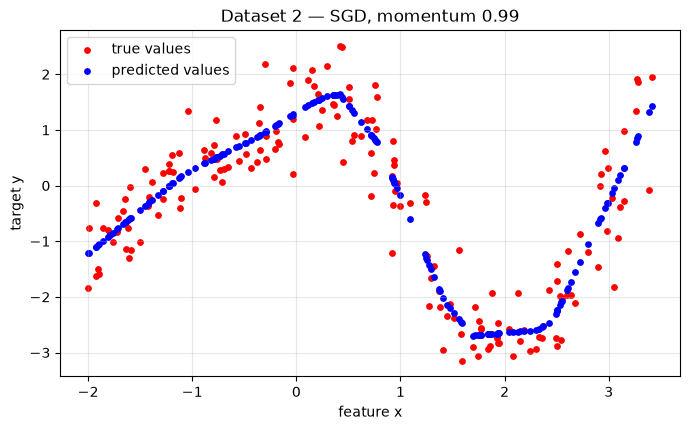

In [17]:
#plotting for our best solver
#plt.title("SGD, momentum 0.99"); plt.grid(alpha=.3); plt.show()
plot_predictions(models["SGD, momentum 0.99"], X2, y2, "Dataset 2 — SGD, momentum 0.99")

## Part 4 – Selecting the best architecture
### Q14. Train / test split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X2, y2, test_size=0.2, random_state=0)
print("train:", X_train.shape[0], "samples | test:", X_test.shape[0], "samples")

train: 141 samples | test: 36 samples


### Q15. Ten networks with 4 neurons and different random states

In [15]:
scores = []
for rs in range(10):
    m = make_mlp(n_neurons=4, random_state=rs).fit(X_train, y_train)
    scores.append(m.score(X_test, y_test))
    print(f"random_state={rs}: test R² = {scores[-1]:.3f}")
print(f"\nmean = {np.mean(scores):.3f}, std = {np.std(scores):.3f}, min = {min(scores):.3f}, max = {max(scores):.3f}")

random_state=0: test R² = 0.781
random_state=1: test R² = 0.800
random_state=2: test R² = 0.665
random_state=3: test R² = 0.411
random_state=4: test R² = 0.188
random_state=5: test R² = 0.333
random_state=6: test R² = 0.218
random_state=7: test R² = 0.801
random_state=8: test R² = 0.572
random_state=9: test R² = -0.023

mean = 0.475, std = 0.278, min = -0.023, max = 0.801


**What the random state impacts.** In an MLP, `random_state` controls the **initialisation of the weights and biases**, and the shuffling of the samples between mini-batches (and the validation split if early stopping is used). The architecture, the data and the hyperparameters are identical for all ten networks: only the starting point of the optimisation changes.

**Results.** The test R² varies from −0.02 to 0.80 (mean 0.48, std 0.28).

**"Neural networks are unstable".** The loss function of a neural network is **non-convex**: it has many local minima, saddle points and plateaus. Gradient descent ends up in whichever basin is closest to its random starting point. Two networks that are "identical" on paper can therefore converge to very different solutions and give very different scores. With only 4 ReLU neurons the problem is worse: some neurons can "die" (always output 0), which leaves even less capacity. A single training run is therefore not a reliable measure of an architecture. We need to average over several random states, which is what we do in Q16–17.

### Q16. Mean and standard deviation over 20 random states

In [ ]:
from matplotlib.pylab import std


def evaluate_neurons(n_neurons, n_runs=20):
    s = [make_mlp(n_neurons=n_neurons, random_state=rs).fit(X_train, y_train).score(X_test, y_test)
         for rs in range(n_runs)]
    return f'{{np.mean(s):.3g}}, {{np.std(s):.3g}}'
evaluate_neurons(4)

SyntaxError: invalid decimal literal (1466123075.py, line 7)

### Q17. From 2 to 30 neurons

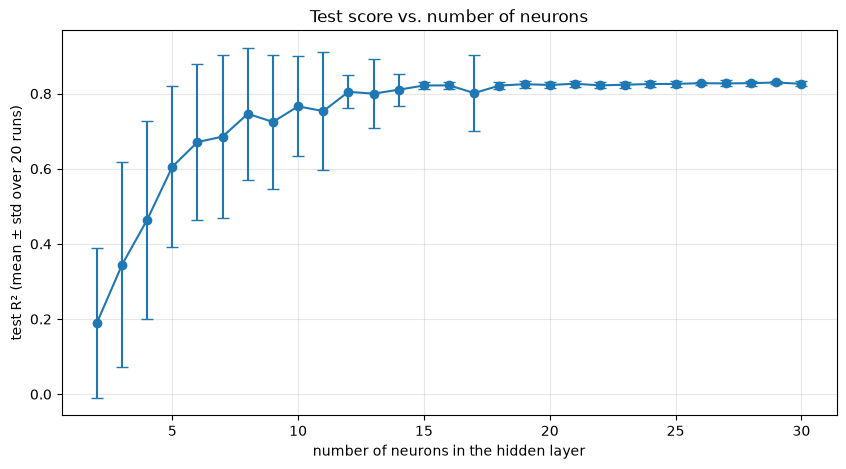

 2 neurons: mean R² = 0.190  std = 0.200
 3 neurons: mean R² = 0.344  std = 0.273
 4 neurons: mean R² = 0.464  std = 0.264
 5 neurons: mean R² = 0.605  std = 0.215
 6 neurons: mean R² = 0.671  std = 0.207
 7 neurons: mean R² = 0.686  std = 0.217
 8 neurons: mean R² = 0.746  std = 0.175
 9 neurons: mean R² = 0.725  std = 0.177
10 neurons: mean R² = 0.766  std = 0.133
11 neurons: mean R² = 0.753  std = 0.156
12 neurons: mean R² = 0.805  std = 0.044
13 neurons: mean R² = 0.800  std = 0.092
14 neurons: mean R² = 0.810  std = 0.042
15 neurons: mean R² = 0.822  std = 0.009
16 neurons: mean R² = 0.822  std = 0.009
17 neurons: mean R² = 0.801  std = 0.100
18 neurons: mean R² = 0.821  std = 0.009
19 neurons: mean R² = 0.825  std = 0.009
20 neurons: mean R² = 0.823  std = 0.008
21 neurons: mean R² = 0.826  std = 0.008
22 neurons: mean R² = 0.822  std = 0.008
23 neurons: mean R² = 0.824  std = 0.008
24 neurons: mean R² = 0.825  std = 0.009
25 neurons: mean R² = 0.826  std = 0.008
26 neurons: mean

In [21]:
neurons = list(range(2, 31))
results = [evaluate_neurons(n) for n in neurons]
means = np.array([r[0] for r in results]); stds = np.array([r[1] for r in results])

plt.figure(figsize=(10, 5))
plt.errorbar(neurons, means, yerr=stds, fmt="o-", capsize=4)
plt.xlabel("number of neurons in the hidden layer"); plt.ylabel("test R² (mean ± std over 20 runs)")
plt.title("Test score vs. number of neurons"); plt.grid(alpha=.3); plt.show()

for n, m_, s_ in zip(neurons, means, stds):
    print(f"{n:2d} neurons: mean R² = {m_:.3f}  std = {s_:.3f}")

### Q18. Chosen architecture

**Answer.** We would choose **about 15 neurons**.

- Below ~12 neurons, the network lacks capacity. The mean score is lower, and above all the standard deviation is large (0.13 to 0.27): results depend heavily on the initialisation.
- From 15 neurons, the curve reaches a **plateau**. The mean R² is around 0.82 and the standard deviation drops to ≈0.01, so almost every initialisation leads to the same good solution.
- Beyond that, adding neurons brings no significant gain. The best mean (0.830 at 29 neurons) is within the noise of the 15-neuron score (0.822). It does make the model larger, slower and more prone to overfitting.

Following the principle of parsimony (Occam's razor), we pick the smallest architecture on the plateau,ex: ~15 neurons. It is accurate and stable. (Note: 17 neurons shows a larger std = 0.10, caused by a single bad initialisation, which is another illustration of the instability seen in Q15.)

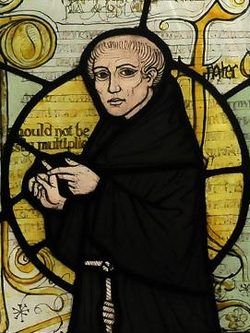